In [1]:
from anemone.physics import *
from anemone import constants as c
from anemone.experiment import Receiver
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
sigma = 1/np.array([2, 80, 200, 80])
sigma = 10/np.array([0.1, 10, 10])
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.tensor([40, 40])

omega = torch.tensor([2000, 2010], dtype=torch.float64)*2*c.pi
lamda = torch.logspace(-2,4, 201, dtype=torch.float64)

In [3]:
x,y,z = torch.linspace(-50, 50, 200), torch.linspace(-50, 50, 76), torch.linspace(0, 160, 301)

In [4]:
rx = Receiver(x, y, z)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:28: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(

In [5]:
len(rx.z)

301

In [6]:
rx.z.shape

torch.Size([301])

In [7]:
from anemone.forwards import Forward
from anemone.physics import transverse_electric_field_coefficients as TEcoef
from anemone.transforms import Hankel

class vert_mag_dipole_FD(Forward):
    sofr = None
    Atot = None
    allr = None

    def __init__(self, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device

        self.allR = torch.sqrt(rx.X**2 + rx.Y**2).to(freqs.device)
        self.rvals = self.allR[..., 0].flatten()
        self.rmin = torch.min(self.allR).to(freqs.device)
        self.rmax = torch.max(self.allR).to(freqs.device)
        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      

    def forward(self):
        omega = c.twopi*self.freqs[:,None]

        def Hz_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]

            if self.Atot is None:
                A,B,un = TEcoef(self.sigma, self.thick, omega, lmb, return_un=True)
                zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
                zsmp = self.receiver.z

                i_z = torch.searchsorted(zbnd, zsmp)-1
                zbnd[0] = 0.
                dz = zsmp-zbnd[i_z]

                Atot = torch.zeros((zsmp.shape+A[0].shape), dtype=torch.complex128)
                print('Atot shape is ', str(Atot.shape))
                for i in range(len(zbnd)):
                    z_slice = i_z==i
                    if z_slice.any():
                        cz = dz[z_slice][:, None, None]
                        u = un[i][None, ...]
                        cA,cB = A[i][None, ...], B[i][None, ...]
                        Atot[z_slice] = cA * torch.exp(-u*cz) + cB * torch.exp(u*cz)                
                if self.filterfunc is not None:
                    Atot *= self.filterfunc.omega_filter(omega)
                self.Atot = torch.nan_to_num(Atot)

            return torch.squeeze(self.Atot/c.fourpi * lmb**3 / un[0])
        
        def Hr_integrand(wave_length):
            """ Hr from horizontal electric dipole. """
            lmb = wave_length[None, :]
            return torch.squeeze(self.Atot/c.fourpi * lmb**2)            
        
        hklz = Hankel(Hz_integrand, 0, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        hklr = Hankel(Hr_integrand, 1, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)

        HzR = hklz(self.rvals).T.reshape(self.receiver.X.shape)
        HrR = hklr(self.rvals).T.reshape(self.receiver.X.shape)

        H = torch.zeros(HzR.shape+(3,), dtype=HzR.dtype).reshape(self.receiver.X.shape+(3,))
        
        H[..., 0] = HrR*self.receiver.X/self.allR
        H[..., 1] = HrR*self.receiver.Y/self.allR
        H[..., 2] = HzR
        return H

In [8]:
f = torch.tensor([2000.], dtype=torch.float64)

fwr = vert_mag_dipole_FD(rx, f)

In [9]:
H = fwr(sigma, thick)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\physics\physics.py:244: RuntimeWarning: overflow encountered in exp
  euh_p = np.exp( u_n[:-1]*thickness)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\physics\physics.py:261: RuntimeWarning: invalid value encountered in multiply
  Amat[..., i*2+1,i*2+1] =  euh_p[i-1]*u_n[i-1]


Atot shape is  torch.Size([301, 1, 481])


In [10]:
H.shape

torch.Size([200, 76, 301, 3])

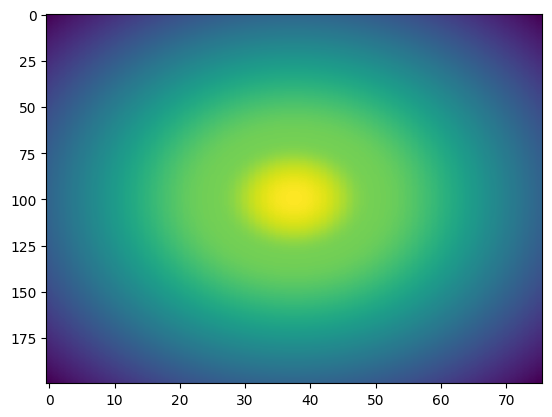

In [11]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 100, 2].numpy())), aspect='auto')

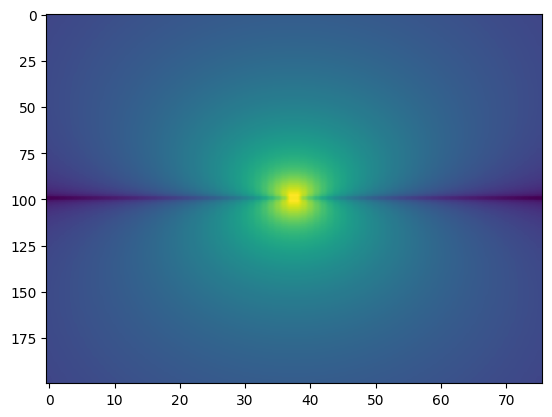

In [12]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 0, 0].numpy())), aspect='auto')

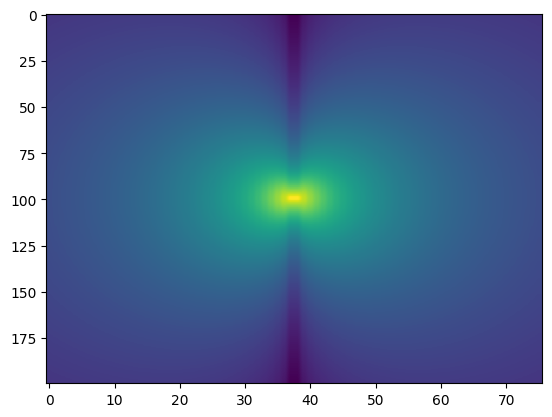

In [13]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 0, 1].numpy())), aspect='auto')

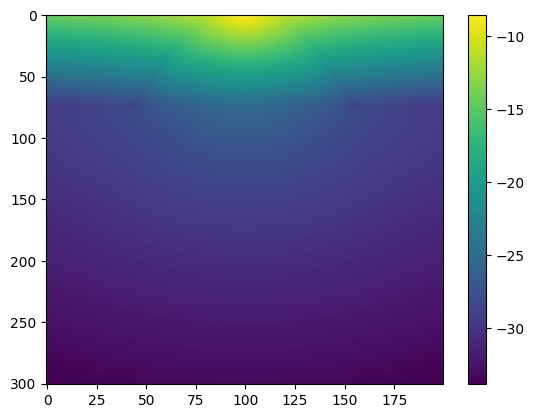

In [15]:
plt.figure()
pcm = plt.imshow(np.log10(np.abs(H[:, 35, :, 1].numpy())).T, aspect='auto')
plt.colorbar(pcm)